# Jupyter Notebook for Exploratory Data Analysis on Final StatsBomb Dataset

In [4]:
import matplotlib.pyplot as plt
import pandas as pd


In [ ]:

# Adjust path to where your final CSV is
PATH = "../statsbomb_pipeline/data/processed/player_season_model_dataset.csv"

df = pd.read_csv(PATH)

df.shape
df.head()
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2131 entries, 0 to 2130
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   player_id             2131 non-null   int64  
 1   player_name           2131 non-null   object 
 2   team_id               2131 non-null   int64  
 3   team_name             2131 non-null   object 
 4   position              2131 non-null   object 
 5   minutes_played_total  2131 non-null   float64
 6   matches_played        2131 non-null   int64  
 7   xThreat_total         2131 non-null   float64
 8   xThreat_pass_total    2131 non-null   float64
 9   xThreat_carry_total   2131 non-null   float64
 10  xg_total              2131 non-null   float64
 11  minutes_90s           2131 non-null   float64
 12  xThreat_per90         2131 non-null   float64
 13  xThreat_pass_per90    2131 non-null   float64
 14  xThreat_carry_per90   2131 non-null   float64
dtypes: float64(9), int64(

,player_id,team_id,minutes_played_total,matches_played,xThreat_total,xThreat_pass_total,xThreat_carry_total,xg_total,minutes_90s,xThreat_per90,xThreat_pass_per90,xThreat_carry_per90
count,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000
mean,10310.017363,32.859221,353.234553,4.854528,0.410232,0.345777,0.064455,0.455681,3.924828,0.101367,0.079522,0.021845
std,13738.200921,11.742299,589.992215,6.713482,0.817809,0.708297,0.213432,1.236511,6.555469,0.422837,0.369157,0.193773
min,2956.000000,1.000000,1.083333,1.000000,-0.889162,-0.929482,-1.162758,0.000000,0.012037,-4.652232,-4.099797,-1.574409
25%,3504.000000,26.000000,30.625000,1.000000,-0.001440,-0.002636,-0.014153,0.000000,0.340278,-0.003450,-0.006886,-0.015147
50%,4217.000000,31.000000,90.000000,2.000000,0.098665,0.080908,0.011055,0.075233,1.000000,0.076171,0.062734,0.008417
75%,10931.000000,39.000000,377.541667,5.000000,0.490145,0.415701,0.084640,0.401173,4.194907,0.185656,0.153994,0.042582
max,129559.000000,59.000000,3420.833333,38.000000,7.742075,7.489739,2.377772,21.635491,38.009259,5.614773,4.733640,3.240654


## Checking for Missing Values

In [3]:
# 1. No zero or near-zero minutes
print("Min minutes_played_total:", df["minutes_played_total"].min())
print("Any zero total minutes?:", (df["minutes_played_total"] == 0).any())

print("Min minutes_90s:", df["minutes_90s"].min())
print("Any zero minutes_90s?:", (df["minutes_90s"] == 0).any())

# 2. No Unknown positions
print("Unique positions:", df["position"].unique())
print("Any 'Unknown' positions?:", (df["position"] == "Unknown").any())

# 3. Any NaNs in key columns?
key_cols = [
    "minutes_played_total",
    "minutes_90s",
    "xThreat_total",
    "xThreat_pass_total",
    "xThreat_carry_total",
    "xg_total"
]
print(df[key_cols].isna().sum())


Min minutes_played_total: 1.0833333333333286
Any zero total minutes?: False
Min minutes_90s: 0.0120370370370369
Any zero minutes_90s?: False
Unique positions: ['Center Forward' 'Right Center Midfield' 'Right Defensive Midfield'
 'Right Wing' 'Center Attacking Midfield' 'Left Midfield' 'Right Midfield'
 'Left Center Forward' 'Left Defensive Midfield' 'Left Wing'
 'Left Center Midfield' 'Left Center Back' 'Right Center Back'
 'Right Attacking Midfield' 'Right Back' 'Left Back' 'Left Wing Back'
 'Right Center Forward' 'Left Attacking Midfield' 'Goalkeeper'
 'Center Defensive Midfield' 'Center Back' 'Right Wing Back']
Any 'Unknown' positions?: False
minutes_played_total    0
minutes_90s             0
xThreat_total           0
xThreat_pass_total      0
xThreat_carry_total     0
xg_total                0
dtype: int64


# Minutes and sample quality


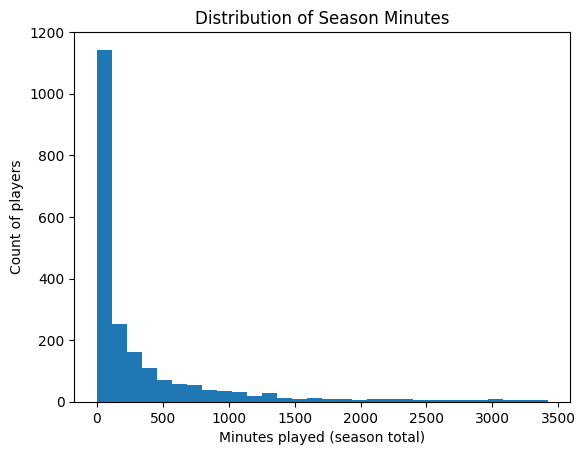

minutes_bucket
<500         1691
500–999       225
1000–1499      94
1500–1999      38
2000–2499      38
2500+          45
Name: count, dtype: int64


In [6]:
# Histogram of total minutes
plt.hist(df["minutes_played_total"], bins=30)
plt.xlabel("Minutes played (season total)")
plt.ylabel("Count of players")
plt.title("Distribution of Season Minutes")
plt.show()

# Quick look at minutes buckets
bins = [0, 500, 1000, 1500, 2000, 2500, 3500]
labels = ["<500", "500–999", "1000–1499", "1500–1999", "2000–2499", "2500+"]

df["minutes_bucket"] = pd.cut(df["minutes_played_total"], bins=bins, labels=labels, include_lowest=True)
print(df["minutes_bucket"].value_counts().sort_index())

### Conclusion
This is an accurate representation of all premier league players. 20 teams with 11 - 14 players = 220 --- 280

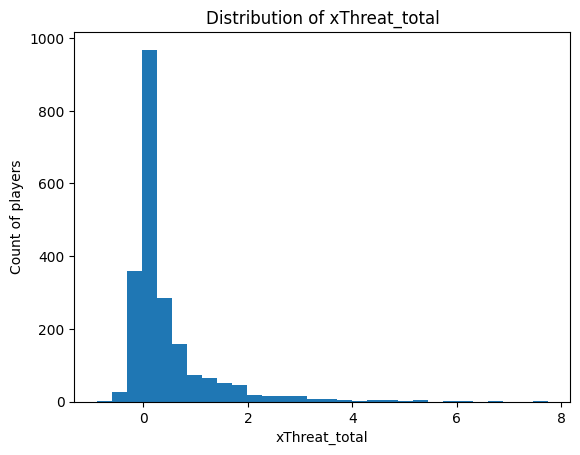

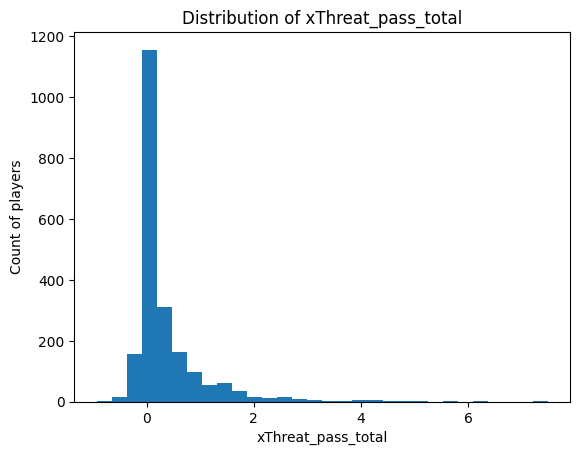

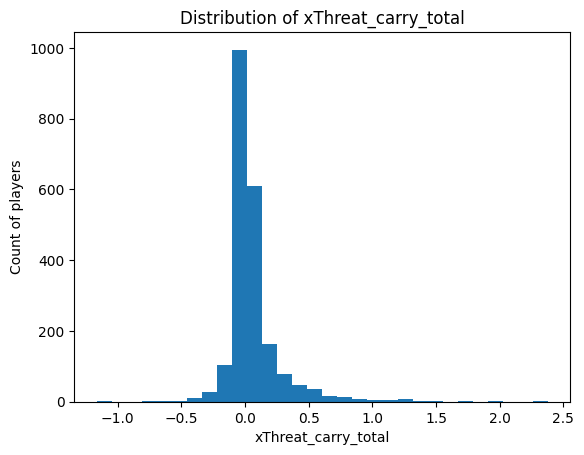

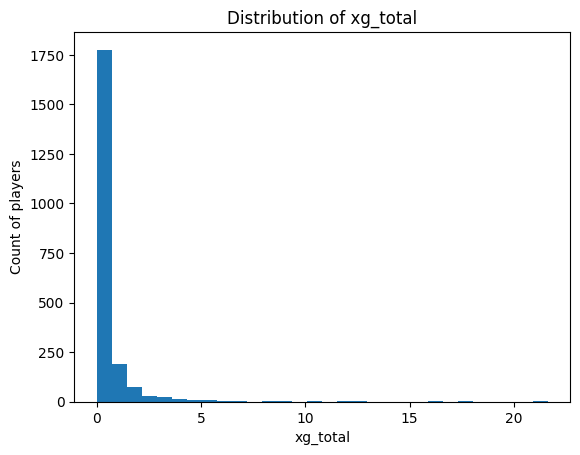

In [7]:
metrics = ["xThreat_total", "xThreat_pass_total", "xThreat_carry_total", "xg_total"]

for col in metrics:
    plt.figure()
    plt.hist(df[col], bins=30)
    plt.xlabel(col)
    plt.ylabel("Count of players")
    plt.title(f"Distribution of {col}")
    plt.show()


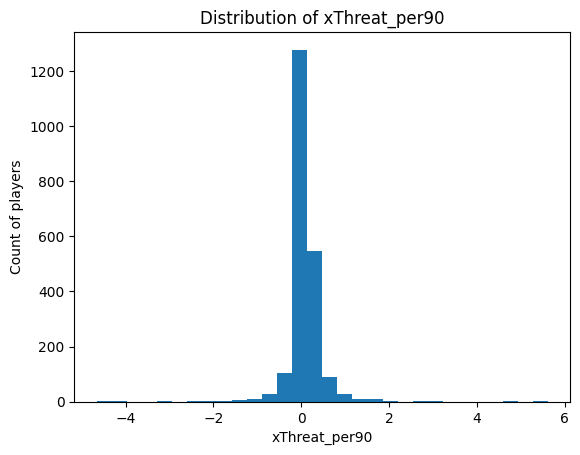

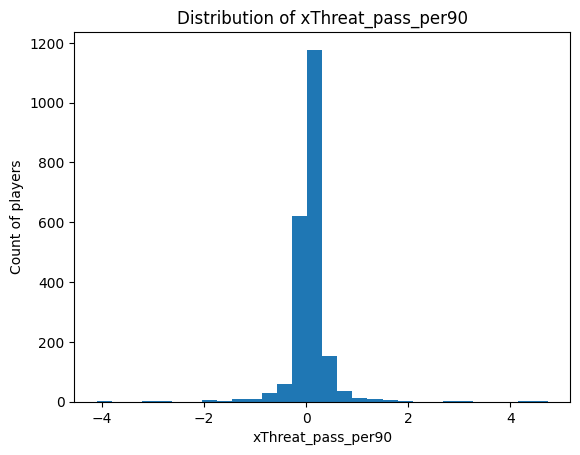

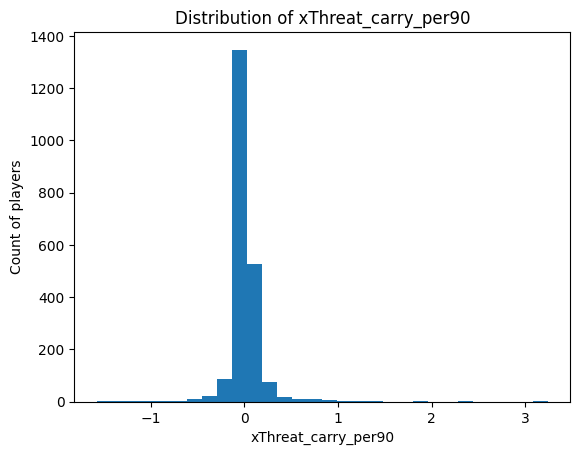

In [8]:
per90_cols = ["xThreat_per90", "xThreat_pass_per90", "xThreat_carry_per90"]

for col in per90_cols:
    plt.figure()
    plt.hist(df[col], bins=30)
    plt.xlabel(col)
    plt.ylabel("Count of players")
    plt.title(f"Distribution of {col}")
    plt.show()


In [10]:
df["position"].value_counts()

df.groupby("position")["minutes_played_total"].describe()

df.groupby("position")[["xThreat_per90", "xg_total", "xThreat_total"]].mean().sort_values(
    "xThreat_per90", ascending=False
)


,xThreat_per90,xg_total,xThreat_total
position,,,
Right Attacking Midfield,0.275484,0.056673,0.191407
Left Center Midfield,0.188412,0.212314,0.323294
Right Wing,0.174019,0.459530,0.352153
Center Attacking Midfield,0.148103,0.527662,0.355840
Left Wing Back,0.129336,0.061222,0.149619
Left Attacking Midfield,0.122450,0.166030,0.117881
Right Wing Back,0.120923,0.102634,0.149248
Center Defensive Midfield,0.118090,0.124044,0.308358
Left Wing,0.113617,0.579984,0.345617


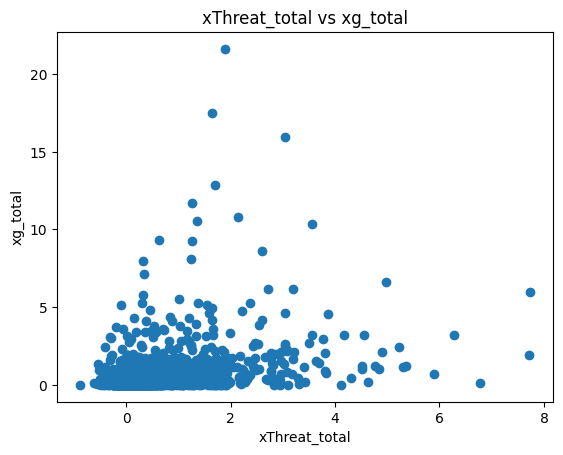

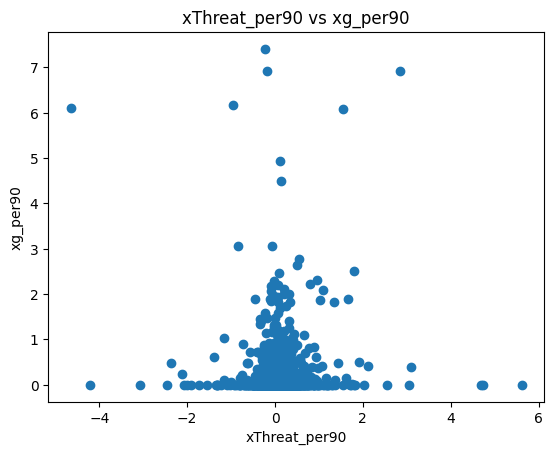

                      minutes_played_total  xThreat_total  xThreat_per90  \
minutes_played_total              1.000000       0.782805       0.004469   
xThreat_total                     0.782805       1.000000       0.175886   
xThreat_per90                     0.004469       0.175886       1.000000   
xg_total                          0.491957       0.388565       0.004520   
xg_per90                         -0.074691      -0.060256      -0.001104   

                      xg_total  xg_per90  
minutes_played_total  0.491957 -0.074691  
xThreat_total         0.388565 -0.060256  
xThreat_per90         0.004520 -0.001104  
xg_total              1.000000  0.142815  
xg_per90              0.142815  1.000000  


In [9]:
# xThreat vs xG totals
plt.scatter(df["xThreat_total"], df["xg_total"])
plt.xlabel("xThreat_total")
plt.ylabel("xg_total")
plt.title("xThreat_total vs xg_total")
plt.show()

# xThreat_per90 vs xg_total or xg_per90 (if you compute it)
df["xg_per90"] = df["xg_total"] / df["minutes_90s"]

plt.scatter(df["xThreat_per90"], df["xg_per90"])
plt.xlabel("xThreat_per90")
plt.ylabel("xg_per90")
plt.title("xThreat_per90 vs xg_per90")
plt.show()

# Quick correlations
corr_cols = ["minutes_played_total", "xThreat_total", "xThreat_per90", "xg_total", "xg_per90"]
print(df[corr_cols].corr())


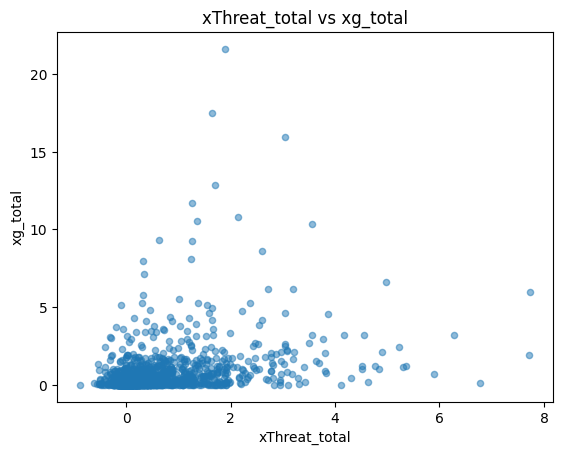

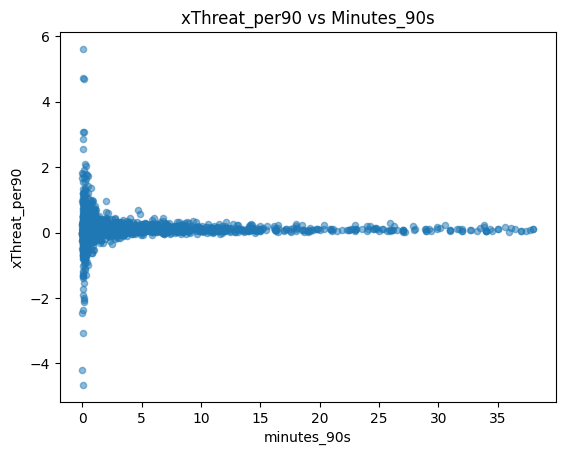

In [11]:
# xThreat vs xG season totals
df.plot.scatter(x="xThreat_total", y="xg_total", alpha=0.5)
plt.title("xThreat_total vs xg_total")
plt.show()

# xThreat_per90 vs minutes_90s to see small-sample madness
df.plot.scatter(x="minutes_90s", y="xThreat_per90", alpha=0.5)
plt.title("xThreat_per90 vs Minutes_90s")
plt.show()


## Final Conclusions


Data is looking great so far. Do need to do some additional cleaning in terms of removing players below the 500 minute mark and 1000 minute mark depending on which model I am running.
I can also standardize certain data in terms of the range and variance depending on the model in order to get better metrics. 

xg_total is our target variable in this study